In [1]:
from sklearn.datasets import make_blobs
import pandas as pd

X, _ = make_blobs(
    n_samples=200,
    centers=3,
    random_state=42
)

df = pd.DataFrame(X, columns=["Feature1","Feature2"])
df.head()

,Feature1,Feature2
0,6.505653,2.447003
1,-5.128943,9.836189
2,-6.891874,-7.777364
3,-8.327712,-8.287573
4,-7.468992,-6.030507


#Exercise 1

Scale the dataset using StandardScaler.

In [2]:
from sklearn.preprocessing import StandardScaler

In [4]:
scaler=StandardScaler()

df_scaled=scaler.fit_transform(df)
df_scaled=pd.DataFrame(df_scaled,columns=df.columns)

df_scaled.head()

,Feature1,Feature2
0,1.681657,0.153575
1,-0.742636,1.284654
2,-1.109977,-1.411491
3,-1.409162,-1.489590
4,-1.230231,-1.144096


#Exercise 2

Apply KMeans clustering with 3 clusters.

Add cluster labels to the dataframe.

Expected column:
```
Cluster
```

In [5]:
from sklearn.cluster import KMeans

In [6]:
kcluster=KMeans(n_clusters=3,random_state=42)

kcluster.fit(df_scaled)

df_scaled["Cluster"]=kcluster.labels_

df_scaled.head()

,Feature1,Feature2,Cluster
0,1.681657,0.153575,2
1,-0.742636,1.284654,0
2,-1.109977,-1.411491,1
3,-1.409162,-1.489590,1
4,-1.230231,-1.144096,1


#Exercise 3

Visualize clusters using a scatter plot.

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

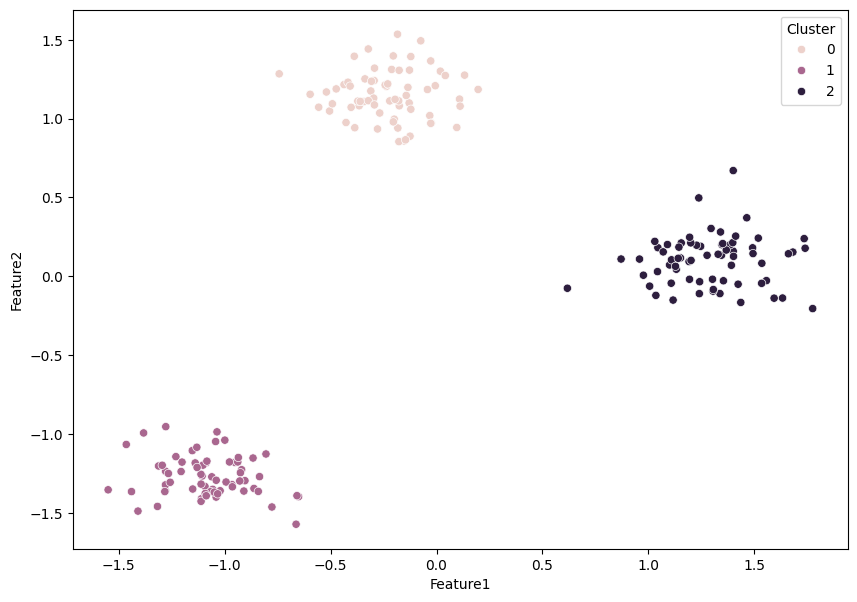

In [8]:
plt.figure(figsize=(10,7))
sns.scatterplot(data=df_scaled,x="Feature1",y="Feature2",hue="Cluster")
plt.show()

#Exercise 4

Use the Elbow Method to test values:
```
K = 1 → 8
```
Plot inertia vs K.

In [12]:
inertia = []

for k in range(1, 9):
    kcluster = KMeans(n_clusters=k, random_state=42)
    kcluster.fit(df_scaled[["Feature1", "Feature2"]])
    inertia.append(kcluster.inertia_)

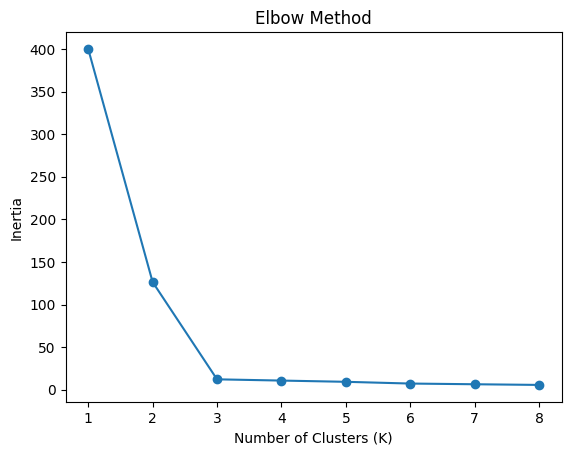

In [13]:
plt.plot(range(1, 9), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

#Exercise 5

* Apply Hierarchical Clustering with 3 clusters.

* Compare results with KMeans.

In [14]:
from sklearn.cluster import AgglomerativeClustering

In [15]:
hc=AgglomerativeClustering(n_clusters=3)
clusters_hc=hc.fit_predict(df_scaled[["Feature1","Feature2"]])

In [16]:
df_scaled["HC_Cluster"] = clusters_hc

print(pd.crosstab(
    df_scaled["Cluster"],
    df_scaled["HC_Cluster"]
))

HC_Cluster   0   1   2
Cluster               
0            0   0  67
1            0  66   0
2           67   0   0


#Exercise 6

Apply DBSCAN clustering.

Experiment with parameters:
```
eps
min_samples
```

In [17]:
from sklearn.cluster import DBSCAN

In [23]:
db=DBSCAN(eps=0.5,min_samples=5)
clusters_db=db.fit_predict(df_scaled[["Feature1","Feature2"]])

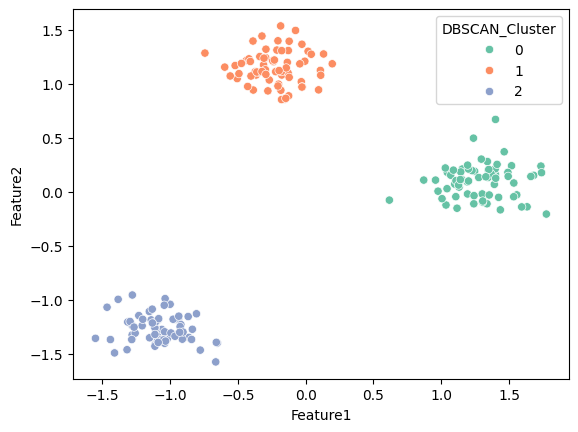

In [24]:
df_scaled["DBSCAN_Cluster"] = clusters_db

sns.scatterplot(
    data=df_scaled,
    x="Feature1",
    y="Feature2",
    hue="DBSCAN_Cluster",
    palette="Set2"
)
plt.show()

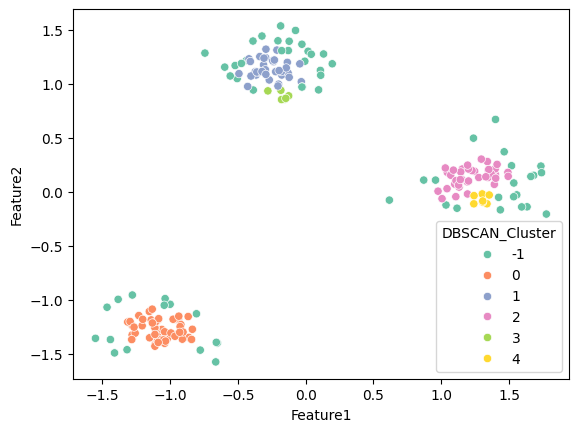

In [30]:
db=DBSCAN(eps=0.1,min_samples=7)
clusters_db=db.fit_predict(df_scaled[["Feature1","Feature2"]])

df_scaled["DBSCAN_Cluster"] = clusters_db

sns.scatterplot(
    data=df_scaled,
    x="Feature1",
    y="Feature2",
    hue="DBSCAN_Cluster",
    palette="Set2"
)
plt.show()

#Exercise 7 (Conceptual)

Answer:

* Why is feature scaling important before applying clustering algorithms?

In [ ]:
# feature scaling is important because clustering algorithms like KMeans rely on distance calculations.
# without scaling, features with larger numerical ranges (such as salary) may dominate the distance calculations
# and influence the clustering results more than other features.